<a href="https://colab.research.google.com/github/YosepAI/TP-Optimisation/blob/master/lab2_Optimization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP 2 — Descente de gradient (version étudiant)

**Méthodes numériques pour les ingénieurs**

Les paramètres et leurs dérivées sont des **nombres séparés** : pas de vecteur pour les paramètres ni pour le gradient. Les couples `(theta1, theta2)` sont conservés dans une liste uniquement pour les graphiques.

Suivre les questions dans l’ordre du sujet.

In [53]:
import numpy as np
import matplotlib.pyplot as plt

# Exercice 1 — Descente de gradient sur une fonction quadratique

## 1.1 Fonction de coût à minimiser

$$J(\theta_1,\theta_2)=\theta_1^2+\theta_2^2$$

**Questions 1–3 :** programmer le coût, calculer analytiquement $\partial J/\partial\theta_1$ et $\partial J/\partial\theta_2$, puis programmer les dérivées. La fonction `gradients_quadratique` retourne **deux nombres séparés par une virgule**.

In [54]:
# TODO : compléter les deux fonctions (paramètres et dérivées séparés).
def cout_quadratique(theta1, theta2):
    return theta1**2 + theta2**2


def gradients_quadratique(theta1, theta2):
    # TODO : retourner deux valeurs séparées par une virgule : dJ/dtheta1, dJ/dtheta2
    return 2*theta1, 2*theta2


print("J(1, 1) =", cout_quadratique(1.0, 1.0))
print("Dérivées en (1, 1) =", gradients_quadratique(1.0, 1.0))

J(1, 1) = 2.0
Dérivées en (1, 1) = (2.0, 2.0)


## 1.2 Algorithme de descente de gradient

Mise à jour des paramètres **séparément** :

$$\theta_1^{(k+1)}=\theta_1^{(k)}-\eta\frac{\partial J}{\partial\theta_1},\qquad
\theta_2^{(k+1)}=\theta_2^{(k)}-\eta\frac{\partial J}{\partial\theta_2}$$

**Questions 1–3 :** coder l’algorithme, commencer en $(1,1)$, choisir $\eta=0.1$ et effectuer 50 itérations en affichant les paramètres et le coût.

**Attention :** calculer `d1` et `d2` au même point **avant** toute mise à jour.

In [55]:
# TODO : compléter la boucle sans vecteur theta ni vecteur gradient.
def gradient_descent(cout_fn, gradients_fn, theta1_init, theta2_init, learning_rate, n_iter):
    theta1, theta2 = float(theta1_init), float(theta2_init)

    history_theta = [(theta1, theta2)]
    cost_history = [cout_fn(theta1, theta2)]  # TODO : enregistrer le coût initial

    for i in range(n_iter):
        # TODO 1 : calculer d1 et d2 au point actuel (theta1, theta2)
        d1, d2 = gradients_fn(theta1,theta2)
        # TODO 2 : mettre à jour theta1 et theta2, chacun séparément
        theta1 = theta1 - learning_rate*d1
        theta2 = theta2 - learning_rate*d2
        # TODO 3 : ajouter les deux paramètres et le coût aux historiques
        history_theta.append((theta1,theta2))
        cost_history.append(cout_fn(theta1,theta2))



        print(f"Itération {i+1:2d} : theta1={theta1:.6f}, "
                f"theta2={theta2:.6f}, J={cost_history[-1]:.8f}")

    return theta1, theta2, history_theta, cost_history


theta1_q, theta2_q, hist_q, costs_q = gradient_descent(cout_quadratique, gradients_quadratique, 1, 1, 0.1, 50)

Itération  1 : theta1=0.800000, theta2=0.800000, J=1.28000000
Itération  2 : theta1=0.640000, theta2=0.640000, J=0.81920000
Itération  3 : theta1=0.512000, theta2=0.512000, J=0.52428800
Itération  4 : theta1=0.409600, theta2=0.409600, J=0.33554432
Itération  5 : theta1=0.327680, theta2=0.327680, J=0.21474836
Itération  6 : theta1=0.262144, theta2=0.262144, J=0.13743895
Itération  7 : theta1=0.209715, theta2=0.209715, J=0.08796093
Itération  8 : theta1=0.167772, theta2=0.167772, J=0.05629500
Itération  9 : theta1=0.134218, theta2=0.134218, J=0.03602880
Itération 10 : theta1=0.107374, theta2=0.107374, J=0.02305843
Itération 11 : theta1=0.085899, theta2=0.085899, J=0.01475740
Itération 12 : theta1=0.068719, theta2=0.068719, J=0.00944473
Itération 13 : theta1=0.054976, theta2=0.054976, J=0.00604463
Itération 14 : theta1=0.043980, theta2=0.043980, J=0.00386856
Itération 15 : theta1=0.035184, theta2=0.035184, J=0.00247588
Itération 16 : theta1=0.028147, theta2=0.028147, J=0.00158456
Itératio

## 1.3 Visualisation de la convergence

**Questions 1–2 :** représenter le coût $J$ en fonction des itérations puis la trajectoire des couples $(\theta_1,\theta_2)$ dans le plan. Le code des graphiques est fourni.

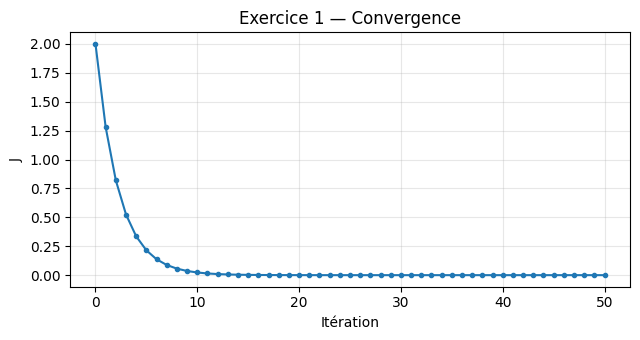

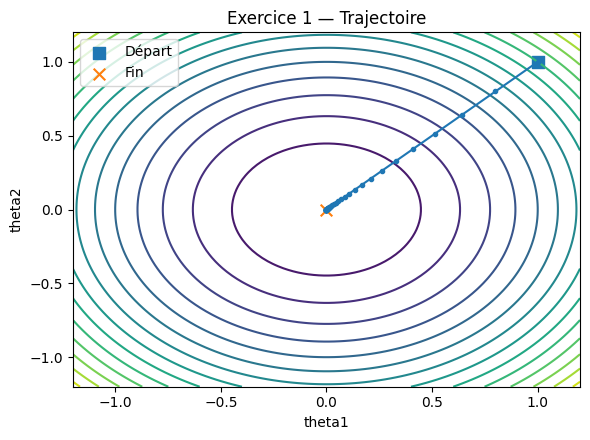

In [56]:
def tracer_cout(cost_history, titre="Convergence du coût"):
    plt.figure(figsize=(6.5, 3.5))
    plt.plot(range(len(cost_history)), cost_history, marker=".")
    plt.xlabel("Itération")
    plt.ylabel("J")
    plt.title(titre)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


def tracer_trajectoire(cout_fn, history_theta, titre="Trajectoire des paramètres"):
    # La liste de couples sert uniquement à dessiner la trajectoire.
    valeurs_1 = [couple[0] for couple in history_theta]
    valeurs_2 = [couple[1] for couple in history_theta]
    t1 = np.linspace(min(min(valeurs_1), -1.2), max(max(valeurs_1), 1.2), 100)
    t2 = np.linspace(min(min(valeurs_2), -1.2), max(max(valeurs_2), 1.2), 100)
    grille1, grille2 = np.meshgrid(t1, t2)
    niveaux = np.array([cout_fn(a, b) for a, b in zip(grille1.ravel(), grille2.ravel())]).reshape(grille1.shape)

    plt.figure(figsize=(6, 4.5))
    plt.contour(grille1, grille2, niveaux, levels=16)
    plt.plot(valeurs_1, valeurs_2, "o-", markersize=3)
    plt.scatter(valeurs_1[0], valeurs_2[0], s=70, marker="s", label="Départ")
    plt.scatter(valeurs_1[-1], valeurs_2[-1], s=70, marker="x", label="Fin")
    plt.xlabel("theta1")
    plt.ylabel("theta2")
    plt.title(titre)
    plt.legend()
    plt.tight_layout()
    plt.show()


tracer_cout(costs_q, "Exercice 1 — Convergence")
tracer_trajectoire(cout_quadratique, hist_q, "Exercice 1 — Trajectoire")

## 1.4 Influence du taux d'apprentissage

**Questions 1–2 :** répéter avec $\eta=0.01$, $0.5$ et $1.0$, puis discuter la vitesse et la stabilité de convergence.

Itération  1 : theta1=0.980000, theta2=0.980000, J=1.92080000
Itération  2 : theta1=0.960400, theta2=0.960400, J=1.84473632
Itération  3 : theta1=0.941192, theta2=0.941192, J=1.77168476
Itération  4 : theta1=0.922368, theta2=0.922368, J=1.70152605
Itération  5 : theta1=0.903921, theta2=0.903921, J=1.63414561
Itération  6 : theta1=0.885842, theta2=0.885842, J=1.56943345
Itération  7 : theta1=0.868126, theta2=0.868126, J=1.50728388
Itération  8 : theta1=0.850763, theta2=0.850763, J=1.44759544
Itération  9 : theta1=0.833748, theta2=0.833748, J=1.39027066
Itération 10 : theta1=0.817073, theta2=0.817073, J=1.33521594
Itération 11 : theta1=0.800731, theta2=0.800731, J=1.28234139
Itération 12 : theta1=0.784717, theta2=0.784717, J=1.23156067
Itération 13 : theta1=0.769022, theta2=0.769022, J=1.18279087
Itération 14 : theta1=0.753642, theta2=0.753642, J=1.13595235
Itération 15 : theta1=0.738569, theta2=0.738569, J=1.09096864
Itération 16 : theta1=0.723798, theta2=0.723798, J=1.04776628
Itératio

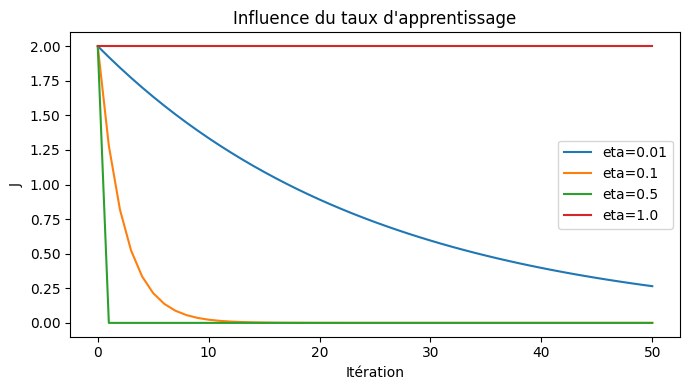

In [57]:
taux_apprentissage = [0.01, 0.1, 0.5, 1.0]
plt.figure(figsize=(7, 4))

for eta in taux_apprentissage:
    t1, t2, historique, couts = gradient_descent(
        cout_quadratique, gradients_quadratique, 1, 1, eta, 50
    )
    plt.plot(couts, label=f"eta={eta}")
    print(f"eta={eta} : theta1={t1:.6f}, theta2={t2:.6f}, J={couts[-1]:.6f}")

plt.xlabel("Itération")
plt.ylabel("J")
plt.title("Influence du taux d'apprentissage")
plt.legend()
plt.tight_layout()
plt.show()

## 1.5 Défi — Fonction plus complexe

$$J(\theta_1,\theta_2)=\theta_1^2+2\theta_2^2+3\sin(\theta_1)\theta_2$$

**Questions 1–3 :** calculer les dérivées partielles, implémenter le coût et les dérivées, puis visualiser la convergence en réutilisant **exactement la même descente de gradient**. Comparer avec la fonction quadratique.

Itération  1 : theta1=0.637909, theta2=0.347559, J=1.26945395
Itération  2 : theta1=0.456894, theta2=0.029880, J=0.25008418
Itération  3 : theta1=0.361840, theta2=-0.114421, J=0.03559896
Itération  4 : theta1=0.301088, theta2=-0.174851, J=-0.00376143
Itération  5 : theta1=0.255954, theta2=-0.193879, J=-0.00656155
Itération  6 : theta1=0.219165, theta2=-0.192278, J=-0.00343730
Itération  7 : theta1=0.187672, theta2=-0.180591, J=-0.00063281
Itération  8 : theta1=0.160127, theta2=-0.164326, J=0.00104467
Itération  9 : theta1=0.135894, theta2=-0.146429, J=0.00183711
Itération 10 : theta1=0.114630, theta2=-0.128500, J=0.00207141
Itération 11 : theta1=0.096094, theta2=-0.111414, J=0.00199095
Itération 12 : theta1=0.080072, theta2=-0.095632, J=0.00175468
Itération 13 : theta1=0.066348, theta2=-0.081375, J=0.00146059
Itération 14 : theta1=0.054694, theta2=-0.068715, J=0.00116562
Itération 15 : theta1=0.044881, theta2=-0.057629, J=0.00089976
Itération 16 : theta1=0.036680, theta2=-0.048037, J=0

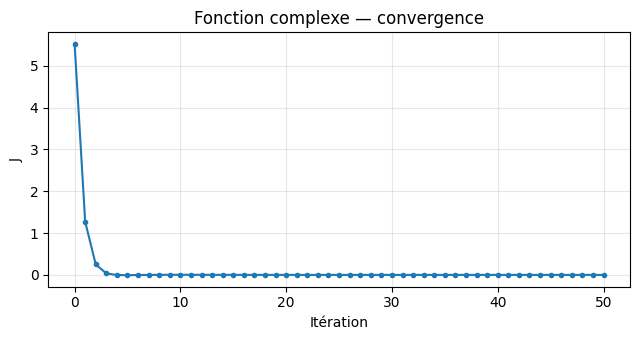

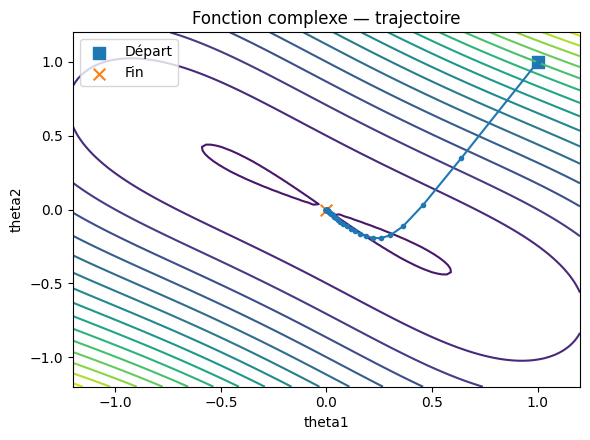

In [58]:
# TODO : compléter les deux fonctions suivantes.
def cout_complexe(theta1, theta2):
    return theta1**2 + 2*(theta2**2) + 3*np.sin(theta1)*theta2


def gradients_complexe(theta1, theta2):
    # TODO : calculer et retourner les deux dérivées partielles séparément
    return 2*theta1 + 3*theta1*np.cos(theta1)*theta2, 4*theta2 + 3*np.sin(theta1)


theta1_c, theta2_c, hist_c, costs_c = gradient_descent(cout_complexe, gradients_complexe, 1, 1, 0.1, 50)
print("Paramètres finaux :", theta1_c, theta2_c, " ; coût :", costs_c[-1])
tracer_cout(costs_c, "Fonction complexe — convergence")
tracer_trajectoire(cout_complexe, hist_c, "Fonction complexe — trajectoire")

# Exercice 2 — Descente de gradient pour la régression linéaire

## 2.1 Introduction

Modèle : $h(x)=\theta_0+\theta_1x$. On minimise :

$$J(\theta_0,\theta_1)=\frac{1}{2m}\sum_{i=1}^{m}(\theta_0+\theta_1x_i-y_i)^2$$

Les dérivées partielles sont :

$$\frac{\partial J}{\partial\theta_0}=\frac1m\sum_i e_i,\qquad\frac{\partial J}{\partial\theta_1}=\frac1m\sum_i e_ix_i,$$

où $e_i=\theta_0+\theta_1x_i-y_i$.

**Attention :** dans cet exercice, les deux paramètres de `gradient_descent` représentent `theta0` (biais) et `theta1` (pente).

## 2.2 Modèle et entraînement

**Questions 1–3 :** générer $m=100$ observations bruitées, programmer le modèle, le coût et les deux dérivées partielles, puis réutiliser la descente de gradient.

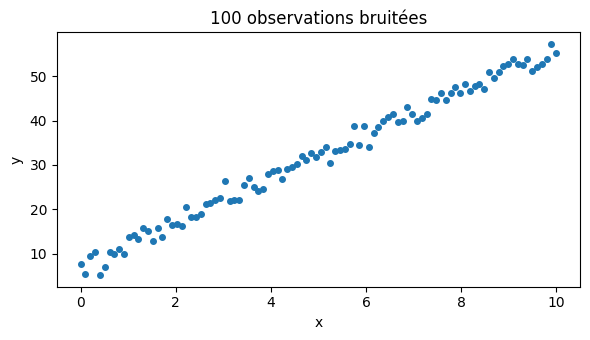

In [59]:
generateur = np.random.default_rng(42)
m = 100
x_data = np.linspace(0, 10, m)
y_data = 7 + 5*x_data + generateur.normal(0, 2, size=m)

plt.figure(figsize=(6, 3.5))
plt.scatter(x_data, y_data, s=16)
plt.xlabel("x")
plt.ylabel("y")
plt.title("100 observations bruitées")
plt.tight_layout()
plt.show()

In [60]:
# TODO : compléter le modèle, le coût et les dérivées partielles.
def predire_lineaire(x, theta0, theta1):
    return theta0 + theta1*x


def cout_lineaire(theta0, theta1):
    # TODO : J = somme des erreurs au carré / (2*m)
    J = 0
    for i in range(1,100):
      J += (theta0 + theta1*x_data[i] - y_data[i])**2
    return J/(2*m)


def gradients_lineaire(theta0, theta1):
    # TODO : retourner dJ/dtheta0, dJ/dtheta1 (deux nombres)
    dJ_1, dJ_2 = 0, 0
    for i in range(1,99):
      dJ_1 += theta0 + theta1*x_data[i] - y_data[i]
      dJ_2 += (theta0 + theta1*x_data[i] - y_data[i])*x_data[i]
    return dJ_1/m, dJ_2/m


# TODO : compléter l'appel à gradient_descent (theta0=0, theta1=0, eta=0.01, 1500 itérations)
theta0_lr, theta1_lr, hist_lr, costs_lr = gradient_descent(cout_lineaire,gradients_lineaire,0,0,0.01,1500)
print("Biais theta0 :", theta0_lr)
print("Pente theta1 :", theta1_lr)
print("Coût final :", costs_lr[-1])

Itération  1 : theta1=0.312715, theta2=1.957735, J=275.67913218
Itération  2 : theta1=0.526436, theta2=3.263850, J=125.82612989
Itération  3 : theta1=0.674063, theta2=4.134983, J=59.17389383
Itération  4 : theta1=0.777558, theta2=4.715750, J=29.55130356
Itération  5 : theta1=0.851581, theta2=5.102686, J=16.39918714
Itération  6 : theta1=0.905918, theta2=5.360235, J=10.56628387
Itération  7 : theta1=0.947104, theta2=5.531413, J=7.98144888
Itération  8 : theta1=0.979498, theta2=5.644937, J=6.83504080
Itération  9 : theta1=1.006011, theta2=5.719977, J=6.32366708
Itération 10 : theta1=1.028588, theta2=5.769328, J=6.09132917
Itération 11 : theta1=1.048526, theta2=5.801533, J=5.98072448
Itération 12 : theta1=1.066690, theta2=5.822294, J=5.92264647
Itération 13 : theta1=1.083659, theta2=5.835418, J=5.88684848
Itération 14 : theta1=1.099818, theta2=5.843444, J=5.86024708
Itération 15 : theta1=1.115426, theta2=5.848070, J=5.83727519
Itération 16 : theta1=1.130654, theta2=5.850428, J=5.81562725


## 2.3 Visualisation

**Questions 1–2 :** représenter la convergence du coût et la droite de régression sur le nuage de points. Le tracé est fourni.

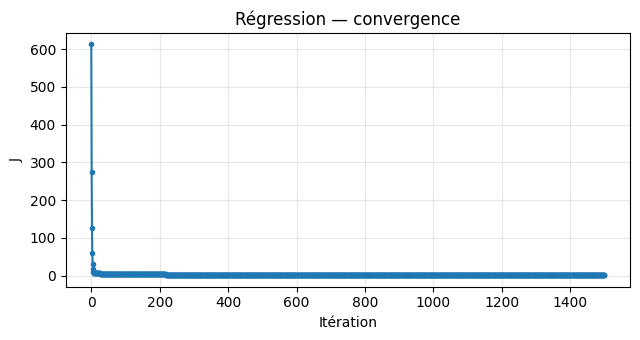

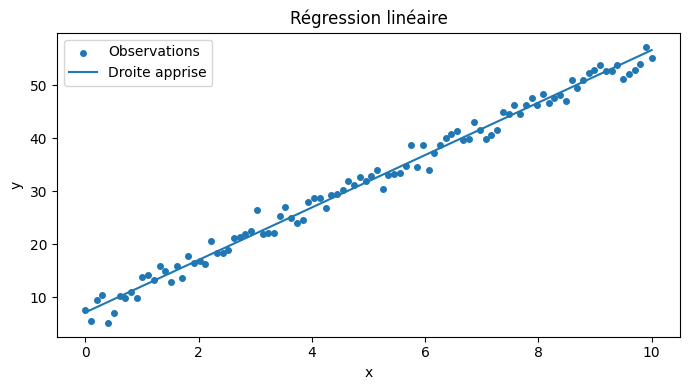

In [61]:
tracer_cout(costs_lr, "Régression — convergence")
plt.figure(figsize=(7, 4))
plt.scatter(x_data, y_data, s=16, label="Observations")
plt.plot(x_data, predire_lineaire(x_data, theta0_lr, theta1_lr), label="Droite apprise")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Régression linéaire")
plt.legend()
plt.tight_layout()
plt.show()

## 2.4 Expérimentation

**Questions 1–2 :** tester plusieurs taux d’apprentissage et comparer avec la solution analytique obtenue par les **équations normales**. Pour la comparaison, utiliser le même jeu de données.

Le flux de sortie a été tronqué et ne contient que les 5000 dernières lignes.
Itération 1005 : theta1=2.242881, theta2=5.690899, J=4.29484325
Itération 1006 : theta1=2.244069, theta2=5.690718, J=4.29337499
Itération 1007 : theta1=2.245257, theta2=5.690538, J=4.29190742
Itération 1008 : theta1=2.246444, theta2=5.690357, J=4.29044054
Itération 1009 : theta1=2.247631, theta2=5.690177, J=4.28897435
Itération 1010 : theta1=2.248818, theta2=5.689997, J=4.28750885
Itération 1011 : theta1=2.250005, theta2=5.689817, J=4.28604404
Itération 1012 : theta1=2.251191, theta2=5.689636, J=4.28457992
Itération 1013 : theta1=2.252377, theta2=5.689456, J=4.28311649
Itération 1014 : theta1=2.253563, theta2=5.689276, J=4.28165374
Itération 1015 : theta1=2.254749, theta2=5.689096, J=4.28019169
Itération 1016 : theta1=2.255934, theta2=5.688916, J=4.27873032
Itération 1017 : theta1=2.257119, theta2=5.688736, J=4.27726964
Itération 1018 : theta1=2.258304, theta2=5.688556, J=4.27580964
Itération 1019 : theta1=2.

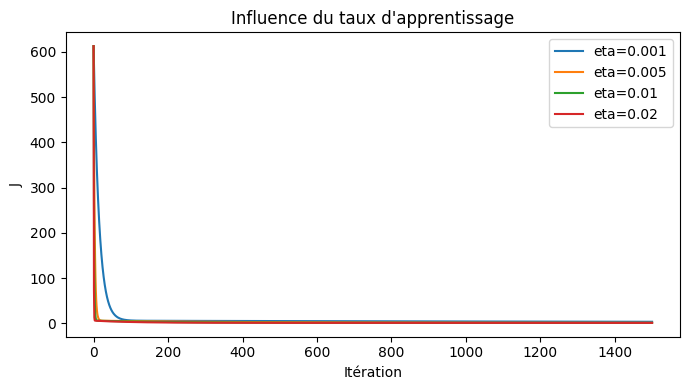


Solution analytique (Équations normales) :
theta0 = 7.3190, theta1 = 4.9161
Écart theta0 : 4.450360e-02
Écart theta1 : 1.068704e-02


In [62]:
taux_apprentissage = [0.001, 0.005, 0.01, 0.02]
plt.figure(figsize=(7, 4))

for eta in taux_apprentissage:

    biais, pente, historique, couts = gradient_descent(cout_lineaire,gradients_lineaire,0,0,eta,1500)
    print(f"eta={eta:.3f} : theta0={biais:.4f}, theta1={pente:.4f}, J={couts[-1]:.6f}")
    plt.plot(couts, label=f"eta={eta}")

plt.xlabel("Itération")
plt.ylabel("J")
plt.title("Influence du taux d'apprentissage")
plt.legend()
plt.tight_layout()
plt.show()

# La matrice X ne sert qu'à la résolution analytique.
X = np.column_stack((np.ones(m), x_data))

# TODO : résoudre X.T @ X @ theta = X.T @ y_data avec np.linalg.solve
solution = np.linalg.solve(X.T @ X,X.T @ y_data)

# TODO : extraire les deux paramètres de la solution
# theta0_normal, theta1_normal = ...
theta0_normal, theta1_normal = solution[0], solution[1]

# TODO : afficher les paramètres et les écarts avec la descente de gradient.
print(f"\nSolution analytique (Équations normales) :")
print(f"theta0 = {theta0_normal:.4f}, theta1 = {theta1_normal:.4f}")

ecart_theta0 = abs(biais - theta0_normal)
ecart_theta1 = abs(pente - theta1_normal)

print(f"Écart theta0 : {ecart_theta0:.6e}")
print(f"Écart theta1 : {ecart_theta1:.6e}")

## Bilan du TP

Expliquer l’effet du taux d’apprentissage sur la vitesse et la stabilité, comparer les fonctions quadratique et complexe, puis comparer les paramètres issus de la descente de gradient et des équations normales.